### **Mel Scale, Mel filterbank**
---

In [1]:
%load_ext autoreload
%autoreload 2

import sys, os
import time
import numpy as np
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio

sys.path.insert(0, os.path.abspath(".."))
from dsp.filters import convolve, fft_convolve
from dsp.signal_generator import make_time, create_sin
from dsp.features import hz_to_mel, mel_to_hz, mel_filterbank

**P1 (ทฤษฎี + โค้ด + หู) Mel scale — อ่าน Wikipedia "Mel scale" ย่อหน้าแรกและหัวข้อ Formula**
  - **ทำ:**
    - สร้าง `notebooks/08_Perception.ipynb` ใช้ `sr = 8000`
    - `pair_low` = 200 Hz 0.5 วินาที ต่อด้วย 300 Hz 0.5 วินาที (แอมพลิจูด 0.5, ใช้ `np.concatenate`) → ยาว 8000 sample
    - `pair_high` = 3000 Hz ต่อด้วย 3100 Hz แบบเดียวกัน
    - ฟังทั้งสองคู่ แล้วเขียน markdown 1 ประโยค: คู่ไหนได้ยินเสียงเปลี่ยนชัดกว่า (ทั้งคู่ห่างกัน 100 Hz)
    > จากการทดลองฟังเสียงแล้วพบว่า `pair_low` ฟังแล้วได้ยินเสียงการเปลี่ยนแปลงที่ชัดเจนกว่า `pair_high`
    - สร้าง `dsp/features.py` แล้วเขียน `hz_to_mel(f)` และ `mel_to_hz(m)` พร้อม docstring
    - ทดสอบ: print `hz_to_mel` ของ 0, 700, 1000 Hz
    - ทดสอบไป-กลับและเทียบ librosa ด้วย `f_test = np.array([0, 440, 4000])` (ใช้ `np.allclose` ทั้งสองอัน)
    - print ระยะ mel ของคู่ต่ำ (300 Hz − 200 Hz) และคู่สูง (3100 Hz − 3000 Hz)
  - **เครื่องมือใหม่:** `10 ** 2` → `100` / `librosa.hz_to_mel(700, htk=True)` → ≈781.17 (`htk=True` = สูตรเดียวกับเรา)
  - **ใบ้:** $m = 2595 \log_{10}(1 + f/700)$ และ $f = 700\,(10^{m/2595} - 1)$ / ใช้ `np.log10` ฟังก์ชันจึงรับ array ได้ / สูตรตั้งให้ 1000 Hz ≈ 1000 mel
  - **ตอบ:**
    1. `hz_to_mel(700)` ได้กี่ mel
    > `hz_to_mel(700)` จะมีค่าเท่ากับ 781.17 mel
    2. ระยะ mel ของคู่ต่ำได้กี่ mel
    > ระยะ mel ของคู่ต่ำมีค่าเท่ากับ 118.74 mel
    3. ระยะ mel ของคู่สูงได้กี่ mel
    > ระยะ mel ของคู่สูงมีค่าเท่ากับ 30.05 mel.
  - **เสร็จเมื่อ:** 0, 700, 1000 Hz ได้ 0, ≈781.17, ≈999.99 mel / `allclose` ได้ True ทั้งสองอัน / คู่ต่ำ ≈118.7 mel คู่สูง ≈30.1 mel / ตอบครบ

In [2]:
sr_p1 = 8000
t_p1 = make_time(0, 0.5, sr_p1)

pair_low = np.concatenate([create_sin(0.5, 200, t_p1), create_sin(0.5, 300, t_p1)])
pair_high = np.concatenate([create_sin(0.5, 3000, t_p1), create_sin(0.5, 3100, t_p1)])

In [3]:
# Listen pair_low 
Audio(pair_low, rate=sr_p1)

In [4]:
# Listen pair_high
Audio(pair_high, rate=sr_p1)

In [5]:
# Test program dsp/features using hz_to_me
F = [0, 700, 1000]
print("Test Program.")
for f in F:
    print(f"Change {f} Hz to {round(hz_to_mel(f),2)} mel.")

print(" ")
# Test with f_test = np.array([0, 440, 4000])
f_test = np.array([0, 440, 4000])
mel_test = hz_to_mel(f_test)

print(f"Convert from Hz to mel : {mel_test}")
print(f"Check hz_to_mel() with librosa.hz_to_mel() : {np.allclose(mel_test, librosa.hz_to_mel(f_test, htk=True))}")
print(f"Convert from mel to Hz : {mel_to_hz(mel_test)}")
print(f"Check mel_to_Hz() with librosa.hz_to_mel() : {np.allclose(mel_to_hz(mel_test), librosa.mel_to_hz(mel_test, htk=True))} \n")

print(f"pair_low in Mel scale : {round(hz_to_mel(300)-hz_to_mel(200),2)} mel.")
print(f"pair_high in Mel scale : {round(hz_to_mel(3100)-hz_to_mel(3000),2)} mel.")
     

Test Program.
Change 0 Hz to 0.0 mel.
Change 700 Hz to 781.17 mel.
Change 1000 Hz to 999.99 mel.
 
Convert from Hz to mel : [   0.          549.63867538 2146.06452751]
Check hz_to_mel() with librosa.hz_to_mel() : True
Convert from mel to Hz : [   0.  440. 4000.]
Check mel_to_Hz() with librosa.hz_to_mel() : True 

pair_low in Mel scale : 118.74 mel.
pair_high in Mel scale : 30.05 mel.


**P2 (โค้ด + สังเกต) Mel filterbank: สามเหลี่ยมที่ห่างเท่ากันบน mel**
  - **ทำ:**
    - `freqs = np.fft.rfftfreq(512, 1/sr)` → ความถี่ (Hz) ของ 257 bin
    - `mel_pts` = 12 จุดห่างเท่ากัน จาก `hz_to_mel(0)` ถึง `hz_to_mel(4000)` (ใช้ `np.linspace`)
    - `hz_pts = mel_to_hz(mel_pts)` แล้ว print `np.diff` ของทั้ง `mel_pts` และ `hz_pts`
    - สร้าง filter ตัวแรก `w` จาก `left, center, right = hz_pts[0], hz_pts[1], hz_pts[2]`: ขึ้นจาก 0 ที่ `left` ถึง 1 ที่ `center` ลงถึง 0 ที่ `right` นอกนั้นเป็น 0
    - พล็อต `w` เทียบ `freqs` และ print `np.sum(w > 0)`
    - เขียน `mel_filterbank(sr, n_fft, n_mels)` ใน `dsp/features.py`: ทำขั้นเดียวกัน แต่ใช้ `n_mels + 2` จุดถึง `sr / 2` แล้ววนสร้าง `fb[i]` จากจุด `i`, `i + 1`, `i + 2`
    - `fb = mel_filterbank(8000, 512, 10)` แล้วเช็ค `fb.shape`, `np.allclose(fb[0], w)` และเทียบ `librosa.filters.mel(sr=8000, n_fft=512, n_mels=10, htk=True, norm=None)`
    - พล็อตทั้ง 10 ตัวในกราฟเดียวด้วยลูป
  - **เครื่องมือใหม่:** `np.linspace(0, 10, 3)` → `[0, 5, 10]` / `np.diff([0, 2, 7])` → `[2, 5]` / `np.minimum([1, 5], [3, 2])` → `[1, 2]` / `np.maximum(0, [-1, 2])` → `[0, 2]`
  - **ใบ้:** ขาขึ้น = `(freqs - left) / (center - left)` ขาลงคิดแบบเดียวกัน แล้วรวมด้วย `np.maximum(0, np.minimum(up, down))` / 12 จุดได้ 10 ตัว เพราะต้องมีขอบซ้ายสุดและขวาสุด / `w.max()` ≈0.947 ไม่ใช่ 1 เพราะ `center` ≈132.3 Hz ไม่ตรง bin ไหน (bin ห่างกัน 15.625 Hz) / `norm=None` = ยอดสูง 1 ทุกตัว
  - **ตอบ:**
    1. `np.diff(mel_pts)` แต่ละช่องกว้างกี่ mel
    > `np.diff(mel_pts)` แต่ละช่องกว้างประมาณ 195.096 mel
    2. `np.diff(hz_pts)` ช่องสุดท้ายกว้างกี่ Hz
    > `np.diff(hz_pts)` ช่องสุดท้ายกว้าง 747.097 Hz
    3. สามเหลี่ยมตัวไหนกว้างที่สุด: ซ้ายสุด (ความถี่ต่ำ) หรือขวาสุด (ความถี่สูง)
    > สามเหลี่ยมตัวที่ 10 มีความกว้างมากที่สุด โดยมีค่าตั้งแต่ประมาณ 2600 - 4000 Hz, ขวาสุด (ความถี่สูง)
  - **เสร็จเมื่อ:** `np.diff(mel_pts)` ≈195.1 mel ทุกช่อง / `np.diff(hz_pts)` ช่องแรก ≈132.3 Hz ช่องสุดท้าย ≈747.1 Hz / `np.sum(w > 0)` ได้ 18 bin / `fb.shape` ได้ `(10, 257)` / เทียบ `w` และ librosa ได้ True / มีกราฟ 10 ตัว และตอบครบ

np.diff() of mel_plt : [195.09677523 195.09677523 195.09677523 195.09677523 195.09677523
 195.09677523 195.09677523 195.09677523 195.09677523 195.09677523
 195.09677523]

np.diff() of hz_plt : [132.29989845 157.30456006 187.03509909 222.38470569 264.4153828
 314.38985179 373.80948817 444.45942721 528.46219447 628.34147256
 747.09791971]

18


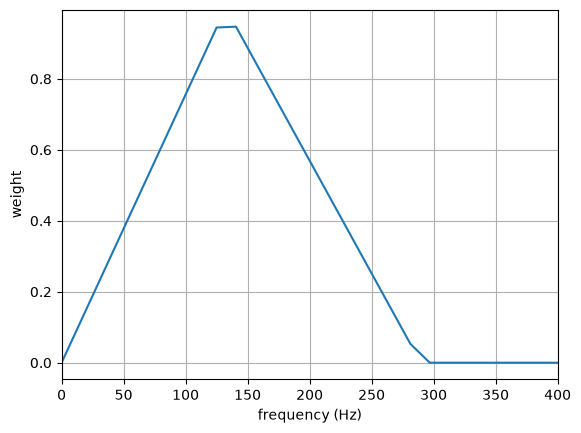

In [6]:
freqs = np.fft.rfftfreq(512, 1/sr_p1)
mel_pts = np.linspace(hz_to_mel(0), hz_to_mel(4000), 12)
hz_pts = mel_to_hz(mel_pts)

print(f"np.diff() of mel_plt : {np.diff(mel_pts)}\n")
print(f"np.diff() of hz_plt : {np.diff(hz_pts)}\n")

left, center, right = hz_pts[0], hz_pts[1], hz_pts[2]

w1 = (freqs - left)/(center - left)
w2 = (freqs - right)/(center - right)
w = np.maximum(0, np.minimum(w1, w2))
print(np.sum(w>0))

fig, ax = plt.subplots()
ax.grid()
ax.set(xlabel="frequency (Hz)", ylabel="weight")
ax.set_xlim(0, 400)
ax.plot(freqs, w)

Shape of fb.shape is (10, 257)

Check np.allclose() of fb[0] with w : True
Check np.allclose() of fb with librosa.filters.mel : True


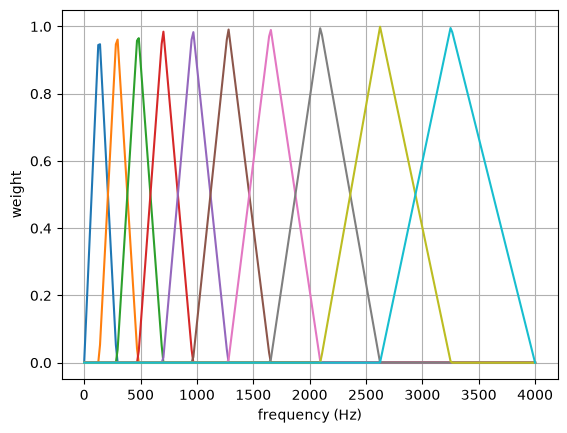

In [ ]:
fb = mel_filterbank(8000, 512, 10)
print(f"Shape of fb.shape is {fb.shape}\n")
print(f"Check np.allclose() of fb[0] with w : {np.allclose(fb[0], w)}")
print(f"Check np.allclose() of fb with librosa.filters.mel : {np.allclose(fb, librosa.filters.mel(sr=8000, n_fft=512, n_mels=10, htk=True, norm=None))}")

fig, ax = plt.subplots()
ax.grid()
ax.set(xlabel="frequency (Hz)", ylabel="weight")
for filt in fb:
    ax.plot(freqs, filt)
